In [1]:
# # On Google Colab, uncomment this cell and run it first.
# # Upload tallinn_osrm_matrix.json and golden_quantum_two_vehicles_angles.npz next to the notebook.
# !pip install -q qiskit qiskit-aer numba pylatexenc

# Golden quantum solution: two vehicles

This notebook solves toy problem 2 from the repository `README.md`: two vans deliver to the Tallinn locations in `tallinn_osrm_matrix.json`, and we minimise the total road distance of both routes. It builds on the one-van notebook, `../problem_1_one_vehicle/golden_quantum_tsp.ipynb`. The leaderboard is in the `README.md` next to this notebook.

**The problem needs one more rule.** As written, the best plan leaves the second van at the depot. We add the reason the README gives for the second van as a distance limit: no van may drive more than 75 % of the shortest one-van tour (30.153 km for 10 locations). Section 2 explains what the limit stands for.

**Result.** On all 10 locations there are 3,628,800 plans. Only 5,576 of them respect the limit, and one pair of routes is the shortest: 48.325 km. We build two circuits. They differ in how they enforce the limit.

| Circuit | Angle tuning | Layers | P(opt): shots that are a shortest plan | P(valid): shots that obey every rule | Cost evaluations for 99 % | CX gates per shot |
|---|---|---|---|---|---|---|
| Hard limit | Linear ramp, 2 tuned numbers | 20 | 24.7 % | 99.9 % | 30,617 | 143 million |
| Hard limit | One mixer angle per layer | 20 | 50.2 % | 99.9 % | 12,607 | 143 million |
| Hard limit | One mixer angle per move | 10 / 20 | 79.4 % / 97.0 % | 99.9 % | 2,733 / 3,602 | 73 / 143 million |
| Soft limit | Linear ramp, 2 tuned numbers | 20 / 40 | 5.6 % / 11.5 % | 78.2 % / 94.1 % | 1,701 / 1,558 | 1.9 / 3.8 million |
| Grover adaptive search | | | | | 4,241 | |
| Random plan | | | 0.00022 % | 0.15 % | 2,088,903 | |

These numbers come from the saved angles. The cells below recompute every one of them.

**What we learned**

- **The second van is free.** A copy of the depot in the list of stops turns two routes into one order. The one-van circuit then works unchanged, with 100 position qubits instead of 81.
- **The distance limit is the expensive part.** It is an inequality on a sum, so the circuit must add up route lengths with quantum arithmetic.
- **Hard limit: the best shots, at a high price.** The circuit checks the limit before every mixer move. Nearly every shot is valid and up to 97 % are the shortest plan. One shot needs 175 qubits and about 143 million CX gates at 20 layers.
- **Soft limit: worse shots, but cheaper overall.** The circuit checks the limit once per layer and adds a penalty. Fewer shots are valid and far fewer are the shortest plan. It still needs the fewest cost evaluations, about 75 times fewer gates per shot, and only two tuned numbers. Its penalty must be chosen with care (section 9).

**How it gets there**

1. **Two routes as one order.** One qubit says "item v is visited at step t". The items are the 9 stops and a copy of the depot. The stops before the copy are the first van's route, the stops after it the second van's.
2. **No invalid answers.** The hard-limit circuit starts in an equal mix of the plans within the limit and every gate keeps it there. The start state comes from amplitude amplification. The mixer is the 2-opt move of the one-van notebook, applied only when it stays within the limit.
3. **A real limit check.** Registers add up both route lengths in metres and compare them with the limit. Section 6 tests this circuit at full size: 137 qubits for the check and 175 qubits for a limit-checked mixer move.
4. **Exact simulation of 175 qubits.** The state never leaves the plans within the limit, so the simulator stores 5,576 amplitudes instead of 2¹⁷⁵. A real Qiskit circuit confirms the simulator on 4 locations.

**What this is not**

- It is not a speed-up over classical computing. Ten locations take a laptop seconds, and the simulator itself lists every plan.
- It does not run on today's quantum computers. Section 11 gives the numbers.
- It uses the symmetric distances only. The one-van notebook also solves the real one-way roads; this notebook does not.
- The full 175-qubit circuit is never simulated as one piece. Its parts are tested separately: the logic on 4 locations, and the arithmetic at full size on single plans.

**How to run**

Run all cells from this directory. With the saved angles in `golden_quantum_two_vehicles_angles.npz` this takes about 2 minutes with `numba` installed. Set `RETRAIN = True` to train again from scratch. That takes about 10 minutes. Without `numba` the notebook still runs, but the soft-limit benchmark in section 9 takes much longer.

# 1. Setup

In [2]:
import itertools
import json
import math
import time
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from scipy.optimize import minimize

try:
    import numba
except ImportError:
    numba = None  # the NumPy simulator below is used instead; the soft-limit benchmark in section 9 then takes minutes

In [3]:
N_LOCATIONS = 10                 # the depot plus 9 stops: every point in the data set
LIMIT_SHARE = 0.75               # no van may drive more than this share of the shortest one-van tour
RETRAIN = False                  # True: ignore the saved angles and train again
ANGLE_FILE = Path("golden_quantum_two_vehicles_angles.npz")
GIBBS_ETA = 8.0                  # how sharply training focuses on the shortest plans
REGISTER_BITS = 18               # qubits in each register that adds up a route length in metres
SOFT_STEP_KM = 9.0               # soft-limit benchmark: extra cost of a plan that breaks the limit
SHOTS = 1000
SEED = 7

DEPTHS_RAMP = (5, 10, 20, 40, 80)        # layers tried with a linear ramp
DEPTHS_PER_LAYER = (5, 10, 20, 40)       # layers trained with one mixer angle per layer
DEPTHS_PER_MOVE = (5, 10, 20)            # layers trained with one mixer angle per move
DEPTHS_SOFT = (20, 40)                   # layers of the soft-limit benchmark
SHOWCASE = ("per move", 20)              # the circuit sampled in section 8

In [4]:
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "lines.markersize": 7,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "legend.frameon": False, "figure.dpi": 110,
})


def show_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def pct(x):
    return f"{100 * x:.1f} %" if x >= 0.01 else f"{100 * x:.2g} %"


def km(metres):
    return f"{metres / 1000:.3f}"

# 2. The problem

Two vans leave the depot. Every stop is visited once, by one of the vans. Both vans return to the depot. We minimise the total road distance of the two routes.

**The distance limit.** Without one more rule this is problem 1 again: the cheapest plan sends one van along the shortest tour and leaves the other at the depot. Section 3 shows this. The README says why the second van is needed: one van cannot cover enough ground. We write that as a limit:

> No van may drive more than 75 % of the shortest one-van tour through the same locations.

For 10 locations the limit is 30.153 km.

**What the limit stands for.** Every parcel must be delivered within one working day. A van spends that day driving and handing over parcels, so the distance it can cover is limited. The real rule would limit time: driving time plus a handover time for each stop. The circuit below adds one number per road driven and compares the sum with a limit. It handles the time rule in the same way, with seconds in place of metres.

**Distances.** As in problem 1, we use one distance per pair of locations, taken from the upper half of the matrix. The data are whole metres, so every sum in this notebook is exact.

In [5]:
DATA_FILE = next(path for path in (Path(up) / "tallinn_osrm_matrix.json" for up in (".", "..", "../..")) if path.exists())
data = json.loads(DATA_FILE.read_text(encoding="utf-8"))
ROAD_METRES = np.array(data["distances"], dtype=np.int64)
NAMES = [point["name"] for point in data["points"]]
LON_LAT = np.array([(point["lon"], point["lat"]) for point in data["points"]])


def distances(n):
    """Distances in metres between the first n locations, plus point n: a copy of the depot. Symmetric (upper half)."""
    upper = np.triu(ROAD_METRES[:n, :n])
    d = np.zeros((n + 1, n + 1), dtype=np.int64)
    d[:n, :n] = upper + upper.T
    d[n, :n] = d[:n, n] = d[0, :n]
    return d


def draw_map(ax, n, routes=None):
    """Locations on a longitude and latitude grid. Routes are drawn with straight lines, not along roads."""
    lon, lat = LON_LAT[:n, 0], LON_LAT[:n, 1]
    for route, color in zip(routes or (), (BLUE, AQUA)):
        loop = [0, *route, 0]
        ax.plot(lon[loop], lat[loop], color=color, zorder=2)
    ax.scatter(lon[1:], lat[1:], s=70, color=INK, zorder=3)
    ax.scatter(lon[:1], lat[:1], s=140, color=ORANGE, marker="s", zorder=3)
    for i in range(n):
        # Point 5 sits just left of point 4, so its label goes on the other side.
        side = -1 if i == 5 else 1
        label = str(i) if routes else f"{i} {NAMES[i].split(' (')[0]}"
        ax.annotate(label, (lon[i], lat[i]), xytext=(8 * side, 7), textcoords="offset points",
                    ha="right" if side < 0 else "left", fontsize=9, color="#52514e")
    ax.set_aspect(1 / math.cos(math.radians(lat.mean())))
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")

# 3. Every plan, and the exact answer

**Two routes as one line.** Add a copy of the depot to the list of stops, as point n. Any order of the n − 1 stops and the depot copy is then a plan for two vans:

- the first van drives the stops before the depot copy,
- the second van drives the stops after it.

If the copy comes first or last, one van stays at the depot. For 10 locations there are 10! = 3,628,800 orders. This is the classical way to turn a problem with several vans into a one-van problem (reference 1).

The same pair of routes appears up to 8 times in the list: the two vans can be swapped, and each route can be driven in either direction.

We list every plan. This gives the exact answer to check against, and the simulator in section 6 needs the list. A real quantum computer would not make this list.

In [6]:
def all_plans(n):
    """Every order of the stops 1..n-1 and the depot copy n, one row per plan, in dictionary order."""
    return np.array(list(itertools.permutations(range(1, n + 1))), dtype=np.int8)


def plan_rank(plans):
    """Row number of each plan in `all_plans`."""
    m = plans.shape[1]
    rank = np.zeros(len(plans), dtype=np.int64)
    for step in range(m - 1):
        rank += (plans[:, step + 1:] < plans[:, step:step + 1]).sum(axis=1) * math.factorial(m - 1 - step)
    return rank


def route_metres(plans, d):
    """Length of the first and of the second route of every plan, in metres."""
    copy = plans.shape[1]
    first = np.zeros(len(plans), dtype=np.int64)
    second = np.zeros(len(plans), dtype=np.int64)
    passed = np.zeros(len(plans), dtype=bool)         # True once the depot copy has been visited
    previous = np.zeros(len(plans), dtype=np.int8)    # both vans start at the depot
    for step in range(copy):
        here = plans[:, step]
        leg = d[previous, here]
        first += np.where(passed, 0, leg)
        second += np.where(passed, leg, 0)
        passed |= here == copy
        previous = here
    return first, second + d[previous, 0]


def routes_of(plan):
    """The two routes of a plan, as tuples of stops."""
    order = [int(v) for v in plan]
    cut = order.index(len(order))
    return tuple(order[:cut]), tuple(order[cut + 1:])


def same_routes(routes):
    """One fixed way to write a pair of routes, whichever van drives which and in whichever direction."""
    return tuple(sorted(min(route, route[::-1]) for route in routes))


def routes_text(routes):
    return " and ".join("0 → " + " → ".join(map(str, route)) + " → 0" if route else "stays at the depot" for route in routes)


@dataclass(frozen=True)
class Instance:
    n: int               # locations, including the depot
    d: np.ndarray        # distances in metres; point n is the depot copy
    plans: np.ndarray    # every plan
    first: np.ndarray    # length of the first route of every plan, metres
    second: np.ndarray   # length of the second route
    total: np.ndarray    # length of both routes together
    one_van: int         # the shortest tour when one van drives everything
    limit: int           # the most a van may drive, metres
    ok: np.ndarray       # True for the plans within the limit
    best: np.ndarray     # True for the shortest plans within the limit

    @property
    def shortest(self):
        return int(self.total[self.best][0])


def make_instance(n, limit_share=LIMIT_SHARE):
    d = distances(n)
    plans = all_plans(n)
    first, second = route_metres(plans, d)
    total = first + second
    one_van = int(total[plans[:, -1] == n].min())
    limit = int(limit_share * one_van)
    ok = np.maximum(first, second) <= limit
    return Instance(n, d, plans, first, second, total, one_van, limit, ok, ok & (total == total[ok].min()))


inst = make_instance(N_LOCATIONS)
M = N_LOCATIONS                      # items to order: the stops and the depot copy
best_plan = inst.plans[inst.best][0]
P_RANDOM = inst.best.mean()

print(f"{len(inst.plans):,} plans. Shortest one-van tour: {km(inst.one_van)} km, so the limit is {km(inst.limit)} km per van.")
print(f"{inst.ok.sum():,} plans are within the limit ({pct(inst.ok.mean())}). {inst.best.sum()} of them are shortest: one pair of routes, written in 8 ways.")
print(f"Shortest plan: {km(inst.shortest)} km ({inst.shortest / inst.one_van - 1:.1%} more than one van).  {routes_text(same_routes(routes_of(best_plan)))}")
print(f"Route lengths: {km(inst.first[inst.best][0])} km and {km(inst.second[inst.best][0])} km")
print(f"A random plan is a shortest plan with probability {pct(P_RANDOM)}. A random plan within the limit: {pct(inst.best.sum() / inst.ok.sum())}.")

3,628,800 plans. Shortest one-van tour: 40.205 km, so the limit is 30.153 km per van.
5,576 plans are within the limit (0.15 %). 8 of them are shortest: one pair of routes, written in 8 ways.
Shortest plan: 48.325 km (20.2% more than one van).  0 → 1 → 3 → 4 → 5 → 9 → 2 → 0 and 0 → 6 → 8 → 7 → 0
Route lengths: 22.410 km and 25.915 km
A random plan is a shortest plan with probability 0.00022 %. A random plan within the limit: 0.14 %.


## What the limit does

The table shows the shortest plan for several limits. With no limit, one van drives everything. A tighter limit forces a more even split, which costs more kilometres. Below about 65 % no plan exists, because the stops in the west need a 25.9 km route.

In [7]:
limit_rows = []
for share in (1.0, 0.9, 0.8, 0.75, 0.65, 0.6):
    limit = int(share * inst.one_van)
    within = np.flatnonzero(np.maximum(inst.first, inst.second) <= limit)
    if len(within) == 0:
        limit_rows.append([f"{share:.0%}", km(limit), "No plan exists", "", "0"])
        continue
    i = within[inst.total[within].argmin()]
    limit_rows.append([f"{share:.0%}", km(limit), km(inst.total[i]), " and ".join(km(v) for v in sorted((inst.first[i], inst.second[i]), reverse=True)),
                       f"{len(within):,}"])
show_table(["Limit, share of the one-van tour", "Limit (km)", "Shortest plan (km)", "Its two routes (km)", "Plans within the limit"], limit_rows)

| Limit, share of the one-van tour | Limit (km) | Shortest plan (km) | Its two routes (km) | Plans within the limit |
|---|---|---|---|---|
| 100% | 40.205 | 40.205 | 40.205 and 0.000 | 311,076 |
| 90% | 36.184 | 42.344 | 32.235 and 10.109 | 113,544 |
| 80% | 32.164 | 44.763 | 30.275 and 14.488 | 18,912 |
| 75% | 30.153 | 48.325 | 25.915 and 22.410 | 5,576 |
| 65% | 26.133 | 48.325 | 25.915 and 22.410 | 240 |
| 60% | 24.123 | No plan exists |  | 0 |

## Check: a second method gives the same answer

Share the stops between the two vans in every possible way. For each van, try every order of its stops. This uses none of the code above.

In [8]:
def shortest_route(stops, d):
    """Shortest loop from the depot through `stops`, by trying every order."""
    if not stops:
        return 0
    orders = np.array(list(itertools.permutations(stops)))
    metres = d[0, orders[:, 0]] + d[orders[:, -1], 0]
    for step in range(len(stops) - 1):
        metres = metres + d[orders[:, step], orders[:, step + 1]]
    return int(metres.min())


def best_split(n, limit):
    """Shortest pair of routes within the limit, by trying every way to share the stops between two vans."""
    d, stops = distances(n), tuple(range(1, n))
    route = {group: shortest_route(group, d) for size in range(n) for group in itertools.combinations(stops, size)}
    pairs = ((route[group], route[tuple(stop for stop in stops if stop not in group)]) for group in route)
    return min(a + b for a, b in pairs if max(a, b) <= limit)


split_answer = best_split(N_LOCATIONS, inst.limit)
assert split_answer == inst.shortest
print(f"Splitting the stops: {km(split_answer)} km. Listing every plan: {km(inst.shortest)} km. They agree.")

Splitting the stops: 48.325 km. Listing every plan: 48.325 km. They agree.


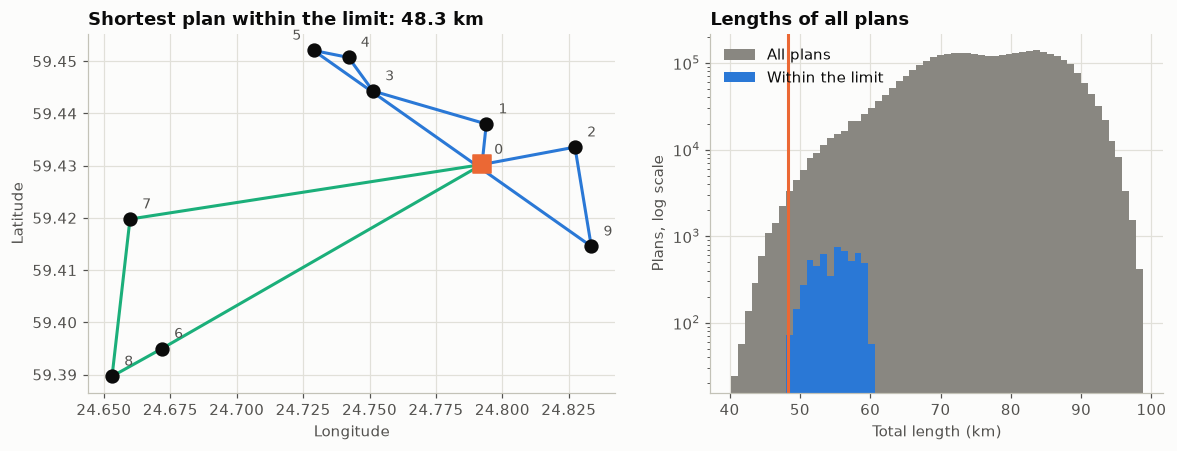

In [9]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
draw_map(left, N_LOCATIONS, same_routes(routes_of(best_plan)))
left.set_title(f"Shortest plan within the limit: {inst.shortest / 1000:.1f} km")
bins = np.linspace(inst.total.min(), inst.total.max(), 61) / 1000
right.hist(inst.total / 1000, bins=bins, color=MUTED, label="All plans")
right.hist(inst.total[inst.ok] / 1000, bins=bins, color=BLUE, label="Within the limit")
right.axvline(inst.shortest / 1000, color=ORANGE)
right.set_yscale("log")
right.set_xlabel("Total length (km)"); right.set_ylabel("Plans, log scale")
right.set_title("Lengths of all plans"); right.legend()
plt.tight_layout(); plt.show()

# 4. The quantum model

## Qubits

We keep the **position encoding** of the one-van notebook. Qubit (v, t) is 1 when item v is visited at step t. The items are the n − 1 stops and the depot copy, so there are n² position qubits: 100 for 10 locations. The limit check in section 5 needs 75 helper qubits. The whole circuit has 175 qubits.

## Two kinds of rules

**Rule 1: every stop is visited once, by one van.** The one-van notebook starts in an equal superposition of all orders and uses a mixer that only reorders. With the depot copy, every order is a pair of routes. This rule therefore costs nothing new: no penalty terms, and every shot is a pair of routes.

**Rule 2: no van drives more than the limit.** This rule is of a different kind. It is an inequality on a sum of distances. Reordering cannot guarantee it, and only 0.15 % of the plans obey it. There are two ways to handle it:

- **Hard limit (the main circuit of this notebook).** The circuit never leaves the plans within the limit. It checks the limit inside the circuit, with quantum arithmetic. Every shot obeys both rules.
- **Soft limit (benchmark in section 9).** The circuit uses all plans. Plans over the limit get a penalty in the cost. Shots can break the limit.

## The hard-limit circuit

**Start state.** We need an equal superposition of the plans within the limit. We start from the equal superposition of all plans and apply amplitude amplification (reference 4), which is Grover search that stops at a superposition instead of one answer. The limit check marks the plans to keep. For 10 locations, 20 rounds move 99.9 % of the probability onto the plans within the limit.

**One layer**

1. **Cost phase.** Each plan gets the phase exp(−iγ·z), where z is its total length as a z-score. The length is a sum over consecutive steps, so this needs only one-qubit and two-qubit phase gates.
2. **Limit-checked 2-opt mixer.** For each stretch of steps a..b, the move R reverses the visiting order inside that stretch. The mixer applies exp(+iβ·R) only when the plan and its reversed partner are both within the limit. All other plans are left alone. This is the controlled mixer of reference 2.

**What a reversal does to two routes.** If the stretch does not contain the depot copy, it reverses part of one van's route. This is the 2-opt move of the one-van notebook. If the stretch contains the depot copy, stops change vans: the end of the first route and the start of the second route are exchanged. Classical vehicle routing calls this a 2-opt* move (reference 10). One family of moves therefore improves each route and also moves stops between the vans.

In [10]:
def segments(m):
    """Step ranges (a, b) that the mixer reverses, shortest first. Reversing all m steps only swaps the two vans, so it is left out."""
    return [(a, a + length - 1) for length in range(2, m) for a in range(m - length + 1)]


def reversal_moves(m):
    moves = []
    for a, b in segments(m):
        order = list(range(m))
        order[a:b + 1] = order[a:b + 1][::-1]
        moves.append(order)
    return moves


print(f"{len(segments(M))} reversal moves per layer for {N_LOCATIONS} locations")

44 reversal moves per layer for 10 locations


# 5. The circuit, gate by gate

These functions build the real circuit in Qiskit. Section 6 uses them to check the simulator, and section 11 counts their gates.

**Parts taken from the one-van notebook**

- **All-plans state.** A quantum version of the Fisher–Yates shuffle, built from W states and controlled swaps.
- **Cost phase.** One phase gate per qubit for the roads to and from the depot, and one controlled-phase gate for every pair "item u at step t, item v at step t + 1".
- **Mixer.** R has eigenvalues +1 and −1. A helper qubit reads which one applies (Hadamard, controlled reversal, Hadamard). A Z rotation on the helper then adds the phase, and the same three gates in reverse clean the helper up.

**New: the limit check**

The limit check adds up the two route lengths in metres and compares each with the limit.

- **Adding.** Two registers of 18 qubits hold the two sums. They work in the Fourier basis, where adding a fixed number takes one phase gate per register qubit (reference 5). Each road "item u at step t − 1, item v at step t" adds its length when both position qubits are 1.
- **Two routes, one adder.** All roads are added to the same register, called `running`. When the depot copy is reached, the two registers are exchanged. The finished first route is then kept in `done`, and `running` starts again from zero for the second route.
- **Comparing.** Each register starts at an offset chosen so that its top qubit becomes 1 exactly when the route is longer than the limit. No separate comparison circuit is needed.

**New: the limit-checked move**

1. Compute the two route lengths of the plan.
2. Reverse the stretch, compute the two route lengths of the partner into a second pair of registers, and reverse the stretch back.
3. Set a flag qubit if all four top qubits are 0: both plans are within the limit.
4. Apply the mixer, controlled by the flag. The controlled reversal also exchanges the two pairs of registers, so that the registers stay correct for both plans.
5. Undo steps 3, 2 and 1. All helper qubits return to 0.

One move therefore runs the limit check four times: twice to compute and twice to undo. We count this as two limit checks, in the same way that one Grover oracle call computes and undoes its test.

In [11]:
def qubit(item, step, m):
    """Index of the qubit that is 1 when item `item` (0..m-1) is visited at step `step`. Item v is location v + 1."""
    return step * m + item


@dataclass(frozen=True)
class Layout:
    """Qubit numbers of the full circuit: the position grid first, then the helper qubits."""
    m: int

    @property
    def helper(self):        # reads the eigenvalue of a reversal in the mixer
        return self.m * self.m

    @property
    def flag(self):          # 1 when a move is allowed
        return self.m * self.m + 1

    @property
    def scratch(self):       # 1 when one given road is driven
        return self.m * self.m + 2

    @property
    def registers(self):     # two pairs of registers for route lengths
        start = self.m * self.m + 3
        return [list(range(start + i * REGISTER_BITS, start + (i + 1) * REGISTER_BITS)) for i in range(4)]

    @property
    def qubits(self):
        return self.m * self.m + 3 + 4 * REGISTER_BITS


def w_state(qc, qubits):
    """Equal superposition of all strings with a single 1 on `qubits`."""
    qc.x(qubits[0])
    for i in range(len(qubits) - 1):
        # Keep amplitude sqrt(1/(k-i)) on qubit i and pass the rest on to qubit i+1.
        qc.cry(2 * math.acos(math.sqrt(1 / (len(qubits) - i))), qubits[i], qubits[i + 1])
        qc.cx(qubits[i + 1], qubits[i])


def all_plans_state(qc, m):
    """Equal superposition of all m! orders."""
    for step in range(m):
        w_state(qc, [qubit(slot, step, m) for slot in range(m - step)])
    # Step `earlier` took slot j, so from then on slot j stands for the last slot that was still free.
    for step in range(m - 1, 0, -1):
        for earlier in range(step - 1, -1, -1):
            for j in range(m - 1 - earlier):
                qc.cswap(qubit(j, earlier, m), qubit(j, step, m), qubit(m - 1 - earlier, step, m))


def cost_phase(qc, gamma, d, m):
    """exp(-i gamma * total metres) on valid orders, up to a global phase."""
    for v in range(m):
        qc.p(-gamma * float(d[0, v + 1]), qubit(v, 0, m))
        qc.p(-gamma * float(d[v + 1, 0]), qubit(v, m - 1, m))
    for step in range(m - 1):
        for u in range(m):
            for v in range(m):
                if u != v:
                    qc.cp(-gamma * float(d[u + 1, v + 1]), qubit(u, step, m), qubit(v, step + 1, m))


def reverse_steps(qc, a, b, m, control=None):
    """Reverse the visiting order of steps a..b, if `control` is 1 (or always, without a control)."""
    for j in range((b - a + 1) // 2):
        for v in range(m):
            if control is None:
                qc.swap(qubit(v, a + j, m), qubit(v, b - j, m))
            else:
                qc.cswap(control, qubit(v, a + j, m), qubit(v, b - j, m))


def reversal_mixer(qc, beta, a, b, m, helper, flag=None, follow=()):
    """exp(+i beta R), where R reverses the visiting order of steps a..b. With `flag`: only where the flag qubit is 1.

    `follow` lists pairs of qubits that are exchanged together with the reversal.
    """
    def controlled_reversal():
        reverse_steps(qc, a, b, m, control=helper)
        for p, q in follow:
            qc.cswap(helper, p, q)

    qc.h(helper); controlled_reversal(); qc.h(helper)
    if flag is None:
        qc.rz(-2 * beta, helper)
    else:
        qc.crz(-2 * beta, flag, helper)
    qc.h(helper); controlled_reversal(); qc.h(helper)


def fourier_start(qc, value, register):
    """Turn a register that holds 0 into the number `value` in the Fourier basis."""
    for k, target in enumerate(register):
        qc.h(target)
        qc.p(2 * math.pi * (value % 2 ** (k + 1)) / 2 ** (k + 1), target)


def fourier_add(qc, value, register, control):
    """Add `value` to a register in the Fourier basis, if `control` is 1."""
    for k, target in enumerate(register):
        angle = 2 * math.pi * (value % 2 ** (k + 1)) / 2 ** (k + 1)
        if angle:
            qc.cp(angle, control, target)


def fourier_read(qc, register):
    """Back to plain binary: register[k] becomes bit k of the number."""
    for k, target in enumerate(register):
        for j in range(k):
            qc.cp(-2 * math.pi * 2 ** j / 2 ** (k + 1), register[j], target)
        qc.h(target)


def route_lengths(qc, m, d, limit, done, running, scratch):
    """The limit check. Afterwards the top qubit of `done` is 1 if the first route is over the limit, and `running` says the same for the second route."""
    offset = 2 ** (REGISTER_BITS - 1) - 1 - limit
    assert offset >= 0 and offset + (m + 1) * int(d.max()) < 2 ** REGISTER_BITS, "REGISTER_BITS is too small for these distances"
    copy = m - 1
    fourier_start(qc, offset, done); fourier_start(qc, offset, running)
    for step in range(m):
        if step == 0:
            for v in range(m):
                fourier_add(qc, int(d[0, v + 1]), running, qubit(v, 0, m))
        else:
            for u in range(m):
                for v in range(m):
                    if u != v:
                        qc.ccx(qubit(u, step - 1, m), qubit(v, step, m), scratch)
                        fourier_add(qc, int(d[u + 1, v + 1]), running, scratch)
                        qc.ccx(qubit(u, step - 1, m), qubit(v, step, m), scratch)
        # The depot copy ends the first route: keep its length in `done` and restart `running`.
        for p, q in zip(done, running):
            qc.cswap(qubit(copy, step, m), p, q)
    for v in range(m):
        fourier_add(qc, int(d[v + 1, 0]), running, qubit(v, m - 1, m))
    fourier_read(qc, done); fourier_read(qc, running)


def limit_checked_move(qc, beta, a, b, m, d, limit):
    """exp(+i beta R) on the pairs of plans that are both within the limit. Every other plan is left alone."""
    lay = Layout(m)
    mine, partner = lay.registers[:2], lay.registers[2:]
    here = QuantumCircuit(lay.qubits)
    route_lengths(here, m, d, limit, *mine, lay.scratch)
    there = QuantumCircuit(lay.qubits)
    reverse_steps(there, a, b, m)
    route_lengths(there, m, d, limit, *partner, lay.scratch)
    reverse_steps(there, a, b, m)
    tops = [register[-1] for register in lay.registers]

    qc.compose(here, inplace=True); qc.compose(there, inplace=True)
    qc.x(tops); qc.mcx(tops, lay.flag); qc.x(tops)
    reversal_mixer(qc, beta, a, b, m, lay.helper, lay.flag, follow=[pair for one, other in zip(mine, partner) for pair in zip(one, other)])
    qc.x(tops); qc.mcx(tops, lay.flag); qc.x(tops)
    qc.compose(there.inverse(), inplace=True); qc.compose(here.inverse(), inplace=True)


def decode(bits, m):
    """Order encoded by the position qubits (bits[i] is qubit i), or None if they are not a valid order."""
    grid = np.array([int(ch) for ch in bits[:m * m]]).reshape(m, m)   # rows: steps, columns: items
    if not (grid.sum(axis=0) == 1).all() or not (grid.sum(axis=1) == 1).all():
        return None
    return tuple(int(v) + 1 for v in grid.argmax(axis=1))


print(f"Full circuit for {N_LOCATIONS} locations: {Layout(M).qubits} qubits "
      f"({M * M} position, {4 * REGISTER_BITS} in four registers, 3 single helpers)")

Full circuit for 10 locations: 175 qubits (100 position, 72 in four registers, 3 single helpers)


# 6. Simulating 175 qubits exactly

A full simulation of 175 qubits is impossible. We do not need one. The hard-limit circuit never leaves the plans within the limit, so the simulator stores one amplitude per such plan: 5,576 complex numbers for 10 locations. Nothing is approximated.

- The **start state** gives every plan within the limit the same amplitude. The 0.1 % of probability that amplitude amplification leaves on other plans stays there: the mixer never moves it. The simulator carries it as missing probability, and it counts against P(valid).
- The **cost phase** multiplies each amplitude by exp(−iγ·z).
- A **mixer move** pairs a plan with its reversed partner, if the partner is also within the limit. Each pair (a, b) becomes (cos β·a + i·sin β·b, cos β·b + i·sin β·a). A plan without such a partner keeps its amplitude.

The same simulator runs the soft-limit benchmark in section 9. There it keeps all 3,628,800 plans.

**Gradients.** Training needs the slope of the objective with respect to every angle. Adjoint differentiation (reference 8) gets all of them from one forward pass and one backward pass. This is only possible in a simulator.

There are two versions of the same maths. The NumPy version is the one to read. The `numba` version is compiled and runs in parallel.

In [12]:
def move_pairs(plans, keep, moves):
    """The pairs of kept plans that each move exchanges.

    Plans are numbered in the order of the kept rows. The pairs of move g are lo[offsets[g]:offsets[g + 1]] and the same slice of hi.
    """
    rows = np.flatnonzero(keep)
    position = np.full(len(plans), -1, dtype=np.int32)
    position[rows] = np.arange(len(rows), dtype=np.int32)
    kept, mine = plans[rows], np.arange(len(rows))
    lo = np.empty(len(moves) * (len(rows) // 2), dtype=np.int32)
    hi = np.empty_like(lo)
    offsets = [0]
    for move in moves:
        partner = position[plan_rank(kept[:, move])]
        pair = np.flatnonzero(partner > mine)             # the partner is kept, and each pair is listed once
        end = offsets[-1] + len(pair)
        lo[offsets[-1]:end], hi[offsets[-1]:end] = pair, partner[pair]
        offsets.append(end)
    return lo[:offsets[-1]], hi[:offsets[-1]], np.array(offsets, dtype=np.int64)


def qaoa_state_numpy(z, lo, hi, offsets, betas, gammas, start):
    """Amplitude of every kept plan after the circuit. `betas` has shape (layers, moves)."""
    psi = start.copy()
    for beta_row, gamma in zip(betas, gammas):
        psi *= np.exp(-1j * gamma * z)
        for g, beta in enumerate(beta_row):
            i, j = lo[offsets[g]:offsets[g + 1]], hi[offsets[g]:offsets[g + 1]]
            a, b = psi[i], psi[j]
            c, s = math.cos(beta), 1j * math.sin(beta)
            psi[i], psi[j] = c * a + s * b, c * b + s * a
    return psi


def qaoa_gradient_numpy(z, lo, hi, offsets, betas, gammas, psi, lam):
    """Slopes of <psi|W|psi> for every angle, given the final state psi and lam = W psi. Changes psi and lam."""
    grad_betas, grad_gammas = np.zeros_like(betas), np.zeros_like(gammas)
    for layer in range(len(gammas) - 1, -1, -1):
        for g in range(betas.shape[1] - 1, -1, -1):
            i, j = lo[offsets[g]:offsets[g + 1]], hi[offsets[g]:offsets[g + 1]]
            a, b, x, y = psi[i], psi[j], lam[i], lam[j]
            grad_betas[layer, g] = -2 * (np.vdot(x, b) + np.vdot(y, a)).imag
            c, s = math.cos(betas[layer, g]), -1j * math.sin(betas[layer, g])
            psi[i], psi[j] = c * a + s * b, c * b + s * a
            lam[i], lam[j] = c * x + s * y, c * y + s * x
        grad_gammas[layer] = 2 * np.vdot(lam, z * psi).imag
        undo = np.exp(1j * gammas[layer] * z)
        psi *= undo; lam *= undo
    return grad_betas, grad_gammas


qaoa_state, qaoa_gradient = qaoa_state_numpy, qaoa_gradient_numpy

if numba is not None:
    # The work is limited by memory speed, so more than 4 threads does not help on this laptop.
    numba.set_num_threads(min(4, numba.get_num_threads()))

    @numba.njit(parallel=True)
    def qaoa_state_numba(z, lo, hi, offsets, betas, gammas, start):
        psi = start.copy()
        for layer in range(gammas.shape[0]):
            gamma = gammas[layer]
            for k in numba.prange(z.shape[0]):
                psi[k] *= np.exp(-1j * gamma * z[k])
            for g in range(offsets.shape[0] - 1):
                c = math.cos(betas[layer, g]); s = 1j * math.sin(betas[layer, g])
                for k in numba.prange(offsets[g], offsets[g + 1]):
                    i = lo[k]; j = hi[k]
                    a = psi[i]; b = psi[j]
                    psi[i] = c * a + s * b
                    psi[j] = c * b + s * a
        return psi

    @numba.njit(parallel=True)
    def qaoa_gradient_numba(z, lo, hi, offsets, betas, gammas, psi, lam):
        grad_betas = np.zeros(betas.shape); grad_gammas = np.zeros(gammas.shape)
        for layer in range(gammas.shape[0] - 1, -1, -1):
            for g in range(offsets.shape[0] - 2, -1, -1):
                c = math.cos(betas[layer, g]); s = -1j * math.sin(betas[layer, g])
                total = 0.0
                for k in numba.prange(offsets[g], offsets[g + 1]):
                    i = lo[k]; j = hi[k]
                    a = psi[i]; b = psi[j]; x = lam[i]; y = lam[j]
                    total += (x.real * b.imag - x.imag * b.real) + (y.real * a.imag - y.imag * a.real)
                    psi[i] = c * a + s * b
                    psi[j] = c * b + s * a
                    lam[i] = c * x + s * y
                    lam[j] = c * y + s * x
                grad_betas[layer, g] = -2 * total
            gamma = gammas[layer]
            total = 0.0
            for k in numba.prange(z.shape[0]):
                a = psi[k]; x = lam[k]
                total += z[k] * (x.real * a.imag - x.imag * a.real)
                undo = np.exp(1j * gamma * z[k])
                psi[k] = a * undo
                lam[k] = x * undo
            grad_gammas[layer] = 2 * total
        return grad_betas, grad_gammas

    qaoa_state, qaoa_gradient = qaoa_state_numba, qaoa_gradient_numba


def grover_rounds(share):
    """Rounds of amplitude amplification that bring a `share` of marked plans closest to 100 %, and the probability reached."""
    angle = math.asin(math.sqrt(share))
    rounds = max(0, round(math.pi / (4 * angle) - 0.5))
    return rounds, math.sin((2 * rounds + 1) * angle) ** 2


class PlanQAOA:
    """The QAOA circuit on the plans marked by `keep`. `cost` is the cost of every plan in metres."""

    def __init__(self, instance, keep, cost, moves, start_probability=1.0):
        self.instance = instance
        self.rows = np.flatnonzero(keep)
        cost = cost[self.rows].astype(float)
        self.std = float(cost.std())
        self.z = (cost - cost.mean()) / self.std
        self.lo, self.hi, self.offsets = move_pairs(instance.plans, keep, moves)
        self.num_moves = len(moves)
        self.start = np.full(len(self.rows), math.sqrt(start_probability / len(self.rows)), dtype=np.complex128)

    def _angles(self, betas, gammas):
        """`betas` is one angle per layer, or one per layer and move."""
        betas = np.asarray(betas, dtype=float)
        if betas.ndim == 1:
            betas = np.repeat(betas[:, None], self.num_moves, axis=1)
        return np.ascontiguousarray(betas), np.ascontiguousarray(gammas, dtype=float)

    def state(self, betas, gammas):
        return qaoa_state(self.z, self.lo, self.hi, self.offsets, *self._angles(betas, gammas), self.start)

    def probabilities(self, betas, gammas):
        psi = self.state(betas, gammas)
        return psi.real ** 2 + psi.imag ** 2

    def value_and_gradient(self, betas, gammas, objective):
        betas, gammas = self._angles(betas, gammas)
        psi = qaoa_state(self.z, self.lo, self.hi, self.offsets, betas, gammas, self.start)
        value, weights = objective(psi.real ** 2 + psi.imag ** 2)
        return value, *qaoa_gradient(self.z, self.lo, self.hi, self.offsets, betas, gammas, psi, weights * psi)


def hard_limit_circuit(instance):
    """The main circuit of this notebook: only plans within the limit, started by amplitude amplification."""
    rounds, reached = grover_rounds(instance.ok.mean())
    return PlanQAOA(instance, instance.ok, instance.total, reversal_moves(instance.n), reached), rounds


hard, PREP_ROUNDS = hard_limit_circuit(inst)
pairs_per_move = np.diff(hard.offsets)
print("Simulator:", "numba, " + str(numba.get_num_threads()) + " threads" if numba is not None else "NumPy")
print(f"Start state: {PREP_ROUNDS} rounds of amplitude amplification put {pct((hard.start @ hard.start.conj()).real)} on the {len(hard.rows):,} plans within the limit")
print(f"Mixer: {hard.num_moves} moves. A move exchanges between {pairs_per_move.min()} and {pairs_per_move.max():,} pairs of plans within the limit.")

Simulator: numba, 4 threads
Start state: 20 rounds of amplitude amplification put 99.9 % on the 5,576 plans within the limit
Mixer: 44 moves. A move exchanges between 0 and 1,842 pairs of plans within the limit.


## Check 1: the two simulators agree, and the gradients are right

In [13]:
small = make_instance(7)
small_hard, _ = hard_limit_circuit(small)
rng = np.random.default_rng(SEED)
test_betas = rng.uniform(0, 0.4, (3, small_hard.num_moves))
test_gammas = rng.uniform(0, 2, 3)

psi_numpy = qaoa_state_numpy(small_hard.z, small_hard.lo, small_hard.hi, small_hard.offsets, test_betas, test_gammas, small_hard.start)
if numba is None:
    print("numba is not installed, so only the NumPy simulator is in use")
else:
    print(f"NumPy against numba, largest amplitude difference: {np.abs(psi_numpy - small_hard.state(test_betas, test_gammas)).max():.1e}")

mean_length = lambda probs: (float(probs @ small_hard.z), small_hard.z)
_, grad_betas, grad_gammas = small_hard.value_and_gradient(test_betas, test_gammas, mean_length)
step = 1e-5


def central_slope(betas_plus, gammas_plus, betas_minus, gammas_minus):
    return (small_hard.probabilities(betas_plus, gammas_plus) - small_hard.probabilities(betas_minus, gammas_minus)) @ small_hard.z / (2 * step)


nudge_beta = np.zeros_like(test_betas); nudge_beta[1, int(np.diff(small_hard.offsets).argmax())] = step
nudge_gamma = np.zeros_like(test_gammas); nudge_gamma[2] = step
slope_beta = central_slope(test_betas + nudge_beta, test_gammas, test_betas - nudge_beta, test_gammas)
slope_gamma = central_slope(test_betas, test_gammas + nudge_gamma, test_betas, test_gammas - nudge_gamma)
print(f"Adjoint gradient against finite differences: beta {abs(grad_betas[nudge_beta > 0][0] - slope_beta):.1e}, gamma {abs(grad_gammas[2] - slope_gamma):.1e}")

NumPy against numba, largest amplitude difference: 3.5e-17


Adjoint gradient against finite differences: beta 5.9e-12, gamma 1.7e-11


## Check 2: the simulator matches a real Qiskit circuit

We build the whole hard-limit circuit for 4 locations and simulate every qubit: amplitude amplification, cost phases and limit-checked moves. The simulator must give the same amplitudes.

The full circuit with its four registers needs 91 qubits even for 4 locations. That is too many to simulate. In this check a lookup table stands in for the limit check: it sets the flag for a listed set of plans. The circuit then has 18 qubits. Check 3 tests the real limit check.

In [14]:
SIMULATOR_GATES = ["cx", "cp", "ccx", "cswap", "swap", "h", "x", "p", "rz", "sx"]


def lookup_flag(qc, marked, m, target):
    """Stand-in for the limit check on tiny instances: flip `target` for every plan in the list `marked`."""
    for plan in marked:
        qc.mcx([qubit(int(item) - 1, step, m) for step, item in enumerate(plan[:-1])], target)


def small_circuit(instance, betas, gammas, rounds, cost_std):
    """The hard-limit circuit for a tiny instance, with lookup tables in place of the limit check."""
    m = instance.n
    grid, helper, flag = list(range(m * m)), m * m, m * m + 1
    ok_plans = instance.plans[instance.ok]
    within = {tuple(plan) for plan in ok_plans.tolist()}
    prepare = QuantumCircuit(m * m + 2)
    all_plans_state(prepare, m)

    qc = prepare.copy()
    for _ in range(rounds):
        qc.x(flag); qc.h(flag); lookup_flag(qc, ok_plans, m, flag); qc.h(flag); qc.x(flag)    # phase -1 on the plans within the limit
        qc.compose(prepare.inverse(), inplace=True)
        qc.x(grid); qc.h(grid[-1]); qc.mcx(grid[:-1], grid[-1]); qc.h(grid[-1]); qc.x(grid)   # phase -1 on the all-zero state
        qc.compose(prepare, inplace=True)
    for beta_row, gamma in zip(betas, gammas):
        cost_phase(qc, gamma / cost_std, instance.d, m)
        for beta, (a, b), move in zip(beta_row, segments(m), reversal_moves(m)):
            both = [plan for plan in ok_plans if tuple(plan[move].tolist()) in within]
            lookup_flag(qc, both, m, flag)
            reversal_mixer(qc, beta, a, b, m, helper, flag)
            lookup_flag(qc, both, m, flag)
    return qc


def plan_bit_index(plans):
    """Position of each plan's bitstring in a statevector, with all helper qubits 0."""
    m = plans.shape[1]
    index = np.zeros(len(plans), dtype=np.int64)
    for step in range(m):
        index += 1 << (step * m + plans[:, step].astype(np.int64) - 1)
    return index


def gate_level_check(n, layers=2):
    instance = make_instance(n)
    circuit, rounds = hard_limit_circuit(instance)
    rng = np.random.default_rng(SEED)
    betas, gammas = rng.uniform(0, 0.4, (layers, circuit.num_moves)), rng.uniform(0, 2, layers)
    qc = transpile(small_circuit(instance, betas, gammas, rounds, circuit.std), basis_gates=SIMULATOR_GATES, optimization_level=0)
    qc.save_statevector()
    full = np.asarray(AerSimulator(method="statevector").run(qc).result().get_statevector())
    on_ok = full[plan_bit_index(instance.plans[instance.ok])]
    on_all = full[plan_bit_index(instance.plans)]
    reference = circuit.state(betas, gammas)
    global_phase = np.vdot(reference, on_ok)
    global_phase /= abs(global_phase)
    return [n, qc.num_qubits, f"{instance.ok.sum()} of {len(instance.plans)}", int(np.diff(circuit.offsets).sum()), rounds,
            f"{np.sum(np.abs(on_all) ** 2):.12f}", f"{np.sum(np.abs(on_ok) ** 2):.6f}", f"{np.sum(np.abs(reference) ** 2):.6f}",
            f"{np.abs(on_ok / global_phase - reference).max():.1e}"]


show_table(["Locations", "Qubits", "Plans within the limit", "Pairs the mixer exchanges", "Amplification rounds", "Probability on valid orders",
            "Probability within the limit, circuit", "The same, simulator", "Largest amplitude difference"],
           [gate_level_check(4)])

| Locations | Qubits | Plans within the limit | Pairs the mixer exchanges | Amplification rounds | Probability on valid orders | Probability within the limit, circuit | The same, simulator | Largest amplitude difference |
|---|---|---|---|---|---|---|---|---|
| 4 | 18 | 8 of 24 | 8 | 1 | 1.000000000000 | 0.925926 | 0.925926 | 2.9e-15 |

## Check 3: the real limit check, at full size

The limit check and the limit-checked move are built for all 10 locations: 137 and 175 qubits. We cannot simulate them on a superposition of all plans. We can run them on one plan at a time. The state then stays simple, and a matrix-product-state simulator handles it.

**The limit check.** We feed in 12 plans: 4 random plans within the limit, 4 random plans, and the 2 plans closest to the limit on each side. The two top qubits must say which routes are over the limit.

In [15]:
mps = AerSimulator(method="matrix_product_state")


def run_on_plan(body, plan, measured, m=M, shots=20):
    """Run a circuit on one plan and measure the listed qubits. Returns {bits: shots}, where bits[i] belongs to measured[i]."""
    qc = QuantumCircuit(body.num_qubits, len(measured))
    for step, item in enumerate(plan):
        qc.x(qubit(int(item) - 1, step, m))
    qc.compose(body, inplace=True)
    qc.measure(measured, range(len(measured)))
    counts = mps.run(transpile(qc, basis_gates=SIMULATOR_GATES, optimization_level=0), shots=shots).result().get_counts()
    return {bits[::-1]: count for bits, count in counts.items()}


lay = Layout(M)
done, running = lay.registers[:2]
limit_check = QuantumCircuit(M * M + 3 + 2 * REGISTER_BITS)
route_lengths(limit_check, M, inst.d, inst.limit, done, running, lay.scratch)

rng = np.random.default_rng(SEED)
within, over = np.flatnonzero(inst.ok), np.flatnonzero(~inst.ok)
longer = np.maximum(inst.first, inst.second)
tested = np.concatenate([rng.choice(within, 4, replace=False), rng.choice(len(inst.plans), 4, replace=False),
                         within[np.argsort(-longer[within])[:2]], over[np.argsort(longer[over])[:2]]])
start_time = time.perf_counter()
wrong = 0
for row in tested:
    counts = run_on_plan(limit_check, inst.plans[row], [done[-1], running[-1]])
    expected = f"{int(inst.first[row] > inst.limit)}{int(inst.second[row] > inst.limit)}"
    wrong += counts != {expected: 20}
print(f"Limit check on {M * M + 1 + 2 * REGISTER_BITS} qubits: {len(tested)} plans tested, {wrong} wrong answers ({time.perf_counter() - start_time:.0f} s)")
print(f"Closest plans: longer route {km(longer[tested[-4]])} km (within the limit of {km(inst.limit)} km) and {km(longer[tested[-2]])} km (over)")

Limit check on 137 qubits: 12 plans tested, 0 wrong answers (11 s)
Closest plans: longer route 30.128 km (within the limit of 30.153 km) and 30.196 km (over)


**The limit-checked move.** We pick the move that exchanges the most pairs of plans and run it on four inputs. With β = π/2 an allowed move turns a plan into its partner with certainty, and with β = π/4 in half of the shots. A plan must stay as it is when it or its partner is over the limit. All 75 helper qubits must return to 0.

In [16]:
busiest = int(pairs_per_move.argmax())
a, b = segments(M)[busiest]
order = reversal_moves(M)[busiest]
partner_ok = inst.ok[plan_rank(inst.plans[:, order])]
cases = [("Plan and partner within the limit", inst.ok & partner_ok, math.pi / 2, "partner"),
         ("Plan and partner within the limit", inst.ok & partner_ok, math.pi / 4, "both"),
         ("Partner over the limit", inst.ok & ~partner_ok, math.pi / 2, "plan"),
         ("Plan over the limit", ~inst.ok & partner_ok, math.pi / 2, "plan")]

move_rows = []
start_time = time.perf_counter()
for label, mask, beta, expected in cases:
    plan = inst.plans[np.flatnonzero(mask)[0]]
    move_circuit = QuantumCircuit(lay.qubits)
    limit_checked_move(move_circuit, beta, a, b, M, inst.d, inst.limit)
    counts = run_on_plan(move_circuit, plan, list(range(lay.qubits)), shots=200)
    seen = Counter()
    for bits, count in counts.items():
        result = decode(bits, M)
        seen["plan" if result == tuple(plan) else "partner" if result == tuple(plan[order]) else "other"] += count
        seen["helpers not 0"] += count * ("1" in bits[M * M:])
    move_rows.append([label, "π/2" if beta > 1 else "π/4", {"partner": "Always the partner", "plan": "Always the plan", "both": "Half each"}[expected],
                      seen["plan"], seen["partner"], seen["other"], seen["helpers not 0"]])
print(f"Move: reverse steps {a}..{b}, on {lay.qubits} qubits ({time.perf_counter() - start_time:.0f} s)")
show_table(["Input", "β", "Expected", "Shots: plan", "Shots: partner", "Shots: anything else", "Shots with a helper qubit not 0"], move_rows)

Move: reverse steps 0..1, on 175 qubits (24 s)


| Input | β | Expected | Shots: plan | Shots: partner | Shots: anything else | Shots with a helper qubit not 0 |
|---|---|---|---|---|---|---|
| Plan and partner within the limit | π/2 | Always the partner | 0 | 200 | 0 | 0 |
| Plan and partner within the limit | π/4 | Half each | 105 | 95 | 0 | 0 |
| Partner over the limit | π/2 | Always the plan | 200 | 0 | 0 | 0 |
| Plan over the limit | π/2 | Always the plan | 200 | 0 | 0 | 0 |

# 7. Choosing the angles

Every angle set below is found without knowing the answer. The optimiser only sees the lengths of the plans the circuit produces.

**Objective.** We minimise the Gibbs objective −log⟨exp(−η·z)⟩ (reference 7), as in the one-van notebook. It rewards putting probability on the very shortest plans.

**Three levels of tuning**

1. **Linear ramp, 2 numbers.** β falls from a start value to zero and γ rises from zero to an end value, like a slow anneal (reference 9). We try 25 slope pairs and keep the best.
2. **One mixer angle per layer, 2p numbers.** Standard QAOA. Starts from the ramp and optimises every angle with L-BFGS.
3. **One mixer angle per move, 45p numbers for 10 locations.** Multi-angle QAOA (reference 6). Each reversal gate gets its own angle.

Levels 2 and 3 use exact gradients. Section 9 counts what the same training would cost on hardware.

In [17]:
def gibbs_objective(z, eta=GIBBS_ETA):
    """-log <exp(-eta z)> and its weights for the gradient. z.min() only keeps the numbers in range."""
    boost = np.exp(-eta * (z - z.min()))

    def objective(probs):
        total = float(probs @ boost)
        return -math.log(total), -boost / total
    return objective


def linear_ramp(layers, slope_beta, slope_gamma):
    position = (np.arange(layers) + 0.5) / layers
    return slope_beta * (1 - position), slope_gamma * position


SLOPES_BETA = (0.1, 0.2, 0.3, 0.45, 0.7)
SLOPES_GAMMA = (1.0, 2.0, 3.0, 4.0, 5.0)


def best_ramp(circuit, layers, slopes_beta=SLOPES_BETA, slopes_gamma=SLOPES_GAMMA):
    """The ramp with the lowest objective on a coarse grid of slopes. Returns (betas, gammas, circuit evaluations)."""
    objective = gibbs_objective(circuit.z)
    scored = []
    for slope_beta in slopes_beta:
        for slope_gamma in slopes_gamma:
            value, _ = objective(circuit.probabilities(*linear_ramp(layers, slope_beta, slope_gamma)))
            scored.append((value, slope_beta, slope_gamma))
    _, slope_beta, slope_gamma = min(scored)
    return *linear_ramp(layers, slope_beta, slope_gamma), len(scored)


def train(circuit, betas0, gammas0, per_move, maxiter):
    """L-BFGS on all angles, starting from one mixer angle per layer. Returns (betas, gammas, circuit evaluations)."""
    layers, moves = len(gammas0), circuit.num_moves
    width = moves if per_move else 1
    objective = gibbs_objective(circuit.z)

    def unpack(x):
        betas = x[:layers * width].reshape(layers, width)
        return (betas if per_move else np.repeat(betas, moves, axis=1)), x[layers * width:]

    def value_and_slopes(x):
        value, grad_betas, grad_gammas = circuit.value_and_gradient(*unpack(x), objective)
        if not per_move:
            grad_betas = grad_betas.sum(axis=1, keepdims=True)
        return value, np.concatenate([grad_betas.ravel(), grad_gammas])

    x0 = np.concatenate([np.repeat(betas0[:, None], width, axis=1).ravel(), gammas0])
    result = minimize(value_and_slopes, x0, jac=True, method="L-BFGS-B", options={"maxiter": maxiter, "maxfun": 2 * maxiter})
    betas, gammas = unpack(result.x)
    return betas if per_move else betas[:, 0], gammas, result.nfev


CACHE = dict(np.load(ANGLE_FILE)) if ANGLE_FILE.exists() and not RETRAIN else {}


def cached_angles(key, compute):
    """Angles saved under `key`, or the result of `compute()`, which is then saved.

    Returns (betas, gammas, circuit evaluations used to find them, seconds that took).
    """
    if f"{key}__gammas" not in CACHE:
        start = time.perf_counter()
        betas, gammas, evaluations = compute()
        CACHE.update({f"{key}__betas": betas, f"{key}__gammas": gammas,
                      f"{key}__evals": np.array(evaluations), f"{key}__seconds": np.array(time.perf_counter() - start)})
        np.savez(ANGLE_FILE, **CACHE)
        print(f"{key}: found in {float(CACHE[f'{key}__seconds']):.0f} s")
    return tuple(CACHE[f"{key}__{part}"] for part in ("betas", "gammas")) + (int(CACHE[f"{key}__evals"]), float(CACHE[f"{key}__seconds"]))

In [18]:
angles = {}   # (level, layers) -> (betas, gammas, circuit evaluations, seconds)

for layers in DEPTHS_RAMP:
    angles["ramp", layers] = cached_angles(f"n{N_LOCATIONS}_ramp_p{layers}", lambda: best_ramp(hard, layers))

for level, depths, per_move, maxiter in (("per layer", DEPTHS_PER_LAYER, False, 600), ("per move", DEPTHS_PER_MOVE, True, 2500)):
    for layers in depths:
        start_betas, start_gammas = angles["ramp", layers][:2]
        angles[level, layers] = cached_angles(
            f"n{N_LOCATIONS}_{level.replace(' ', '_')}_p{layers}",
            lambda: train(hard, start_betas, start_gammas, per_move, maxiter))

print(f"{len(angles)} angle sets ready")

12 angle sets ready


# 8. Results

## The measures

These are the measures of `solutions/README.md`, read for two vans.

1. **P(opt):** the share of shots that return a shortest plan within the limit.
2. **P(valid):** the share of shots that are valid plans: every stop once, and both routes within the limit. Here it is 99.9 %, set by the start state.
3. **Mean gap:** how much longer the average valid shot is than the shortest plan.
4. **Cost evaluations for 99 %:** the shots needed for a 99 % chance of seeing a shortest plan at least once, multiplied by the cost evaluations in one shot.
5. **Circuit cost:** qubits, layers and two-qubit gates (section 11), and the circuit runs used in training.

**Cost evaluations in one shot.** One cost evaluation means working out the route lengths of a plan once. The hard-limit circuit does this:

- once per round of amplitude amplification in the start state (20 rounds),
- once per layer for the cost phase,
- twice per mixer move for the limit check (44 moves per layer),
- once to read the length of the sampled plan.

That is 20 + 89 × layers + 1. The one-van circuit needs layers + 1. The limit check is what makes the hard limit expensive.

In [19]:
def shots_for_99(p_opt):
    if p_opt <= 0:
        return math.inf
    return 1 if p_opt > 1 - 1e-12 else math.ceil(math.log(0.01) / math.log1p(-p_opt))


def measures(circuit, probs, evaluations_per_shot):
    instance, rows = circuit.instance, circuit.rows
    valid, best = instance.ok[rows], instance.best[rows]
    p_valid, p_opt = float(probs[valid].sum()), float(probs[best].sum())
    shots = shots_for_99(p_opt)
    return {"p_opt": p_opt, "p_valid": p_valid, "gap": float(probs[valid] @ instance.total[rows][valid]) / p_valid / instance.shortest - 1,
            "shots": shots, "per_shot": evaluations_per_shot, "evaluations": shots * evaluations_per_shot}


def hard_evaluations_per_shot(layers, rounds=PREP_ROUNDS, moves=hard.num_moves):
    return rounds + layers * (1 + 2 * moves) + 1


def tuned_numbers(level, layers):
    return {"ramp": 2, "per layer": 2 * layers, "per move": (hard.num_moves + 1) * layers}[level]


results = {key: measures(hard, hard.probabilities(betas, gammas), hard_evaluations_per_shot(key[1])) for key, (betas, gammas, _, _) in angles.items()}

show_table(
    ["Angles", "Layers", "Tuned numbers", "P(opt)", "P(valid)", "Mean gap", "Shots to 99 %", "Cost evaluations per shot", "Cost evaluations to 99 %"],
    [[level, layers, tuned_numbers(level, layers), pct(r["p_opt"]), pct(r["p_valid"]), pct(r["gap"]), f"{r['shots']:,}", f"{r['per_shot']:,}",
      f"{r['evaluations']:,}"] for (level, layers), r in results.items()])
print(f"Random plan: P(opt) = {pct(P_RANDOM)}, P(valid) = {pct(inst.ok.mean())}, {shots_for_99(P_RANDOM):,} shots to 99 %")
print(f"Random plan within the limit: P(opt) = {pct(inst.best.sum() / inst.ok.sum())}, mean gap {pct(inst.total[inst.ok].mean() / inst.shortest - 1)}")

| Angles | Layers | Tuned numbers | P(opt) | P(valid) | Mean gap | Shots to 99 % | Cost evaluations per shot | Cost evaluations to 99 % |
|---|---|---|---|---|---|---|---|---|
| ramp | 5 | 2 | 5.7 % | 99.9 % | 4.2 % | 80 | 466 | 37,280 |
| ramp | 10 | 2 | 11.1 % | 99.9 % | 4.7 % | 40 | 911 | 36,440 |
| ramp | 20 | 2 | 24.7 % | 99.9 % | 4.1 % | 17 | 1,801 | 30,617 |
| ramp | 40 | 2 | 32.3 % | 99.9 % | 2.4 % | 12 | 3,581 | 42,972 |
| ramp | 80 | 2 | 58.5 % | 99.9 % | 1.7 % | 6 | 7,141 | 42,846 |
| per layer | 5 | 10 | 6.1 % | 99.9 % | 3.9 % | 74 | 466 | 34,484 |
| per layer | 10 | 20 | 27.1 % | 99.9 % | 3.8 % | 15 | 911 | 13,665 |
| per layer | 20 | 40 | 50.2 % | 99.9 % | 2.4 % | 7 | 1,801 | 12,607 |
| per layer | 40 | 80 | 65.8 % | 99.9 % | 1.5 % | 5 | 3,581 | 17,905 |
| per move | 5 | 225 | 34.5 % | 99.9 % | 4.6 % | 11 | 466 | 5,126 |
| per move | 10 | 450 | 79.4 % | 99.9 % | 1.8 % | 3 | 911 | 2,733 |
| per move | 20 | 900 | 97.0 % | 99.9 % | 0.33 % | 2 | 1,801 | 3,602 |

Random plan: P(opt) = 0.00022 %, P(valid) = 0.15 %, 2,088,903 shots to 99 %
Random plan within the limit: P(opt) = 0.14 %, mean gap 13.8 %


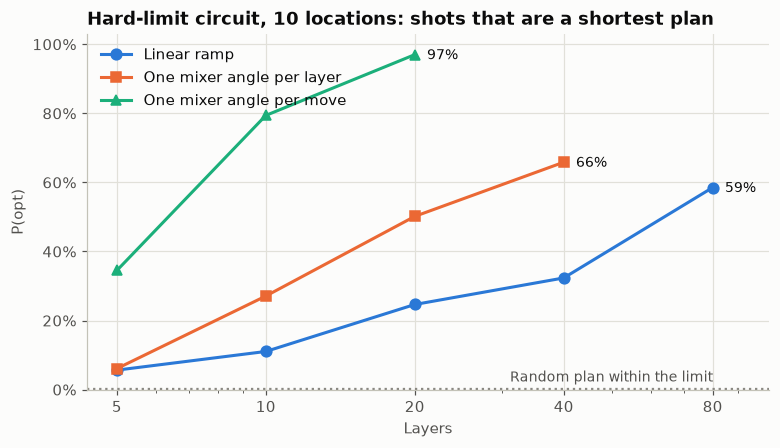

In [20]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for level, color, marker in (("ramp", BLUE, "o"), ("per layer", ORANGE, "s"), ("per move", AQUA, "^")):
    depths = [layers for (lv, layers) in results if lv == level]
    values = [results[level, layers]["p_opt"] for layers in depths]
    ax.plot(depths, values, color=color, marker=marker, label=f"One mixer angle {level}" if level != "ramp" else "Linear ramp")
    ax.annotate(f"{values[-1]:.0%}", (depths[-1], values[-1]), xytext=(8, -3), textcoords="offset points", fontsize=9)
ax.axhline(inst.best.sum() / inst.ok.sum(), color=MUTED, linestyle=":", linewidth=1.5)
ax.annotate("Random plan within the limit", (DEPTHS_RAMP[-1], inst.best.sum() / inst.ok.sum()), xytext=(0, 5), textcoords="offset points", fontsize=9, color="#52514e", ha="right")
ax.set_xscale("log"); ax.set_xticks(DEPTHS_RAMP); ax.set_xticklabels(DEPTHS_RAMP); ax.set_xlim(right=DEPTHS_RAMP[-1] * 1.3)
ax.set_ylim(0, 1.03); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Layers"); ax.set_ylabel("P(opt)")
ax.set_title(f"Hard-limit circuit, {N_LOCATIONS} locations: shots that are a shortest plan"); ax.legend(loc="upper left")
plt.show()

## Sampling the circuit

We now measure one circuit, as a real run would. Each shot is a pair of routes. The same pair can come out in 8 ways (vans swapped, routes reversed), so we count those together.

In [21]:
showcase_betas, showcase_gammas = angles[SHOWCASE][:2]
showcase_probs = hard.probabilities(showcase_betas, showcase_gammas)
rng = np.random.default_rng(SEED)
# The last entry stands for the plans over the limit that amplitude amplification leaves behind. They are all equally likely.
draws = rng.choice(len(showcase_probs) + 1, size=SHOTS, p=np.append(showcase_probs, max(0.0, 1 - showcase_probs.sum())) / max(1.0, showcase_probs.sum()))
over_limit = np.flatnonzero(~inst.ok)
shot_rows = [hard.rows[i] if i < len(showcase_probs) else rng.choice(over_limit) for i in draws]
counts = Counter(routes_of(inst.plans[row]) for row in shot_rows)
merged = Counter()
for routes, count in counts.items():
    merged[same_routes(routes)] += count


def routes_metres(routes, d):
    return [int(d[0, route[0]] + sum(d[a, b] for a, b in zip(route, route[1:])) + d[route[-1], 0]) if route else 0 for route in routes]


print(f"{SHOTS} shots of the '{SHOWCASE[0]}' circuit with {SHOWCASE[1]} layers: {len(merged)} different pairs of routes")
show_table(["Routes", "Route lengths (km)", "Total (km)", "Within the limit", "Shots"],
           [[routes_text(routes), " and ".join(km(v) for v in routes_metres(routes, inst.d)), km(sum(routes_metres(routes, inst.d))),
             "Yes" if max(routes_metres(routes, inst.d)) <= inst.limit else "No", count] for routes, count in merged.most_common(5)])

1000 shots of the 'per move' circuit with 20 layers: 27 different pairs of routes


| Routes | Route lengths (km) | Total (km) | Within the limit | Shots |
|---|---|---|---|---|
| 0 → 1 → 3 → 4 → 5 → 9 → 2 → 0 and 0 → 6 → 8 → 7 → 0 | 22.410 and 25.915 | 48.325 | Yes | 974 |
| 0 → 2 → 5 → 3 → 1 → 9 → 0 and 0 → 4 → 7 → 8 → 6 → 0 | 27.186 and 29.153 | 56.339 | Yes | 1 |
| 0 → 2 → 1 → 4 → 5 → 9 → 0 and 0 → 3 → 7 → 6 → 8 → 0 | 25.200 and 28.257 | 53.457 | Yes | 1 |
| 0 → 1 → 2 → 9 → 4 → 5 → 3 → 0 and 0 → 6 → 8 → 7 → 0 | 25.080 and 25.915 | 50.995 | Yes | 1 |
| 0 → 4 → 7 → 8 → 6 → 0 and 0 → 5 → 3 → 1 → 2 → 9 → 0 | 29.153 and 22.602 | 51.755 | Yes | 1 |

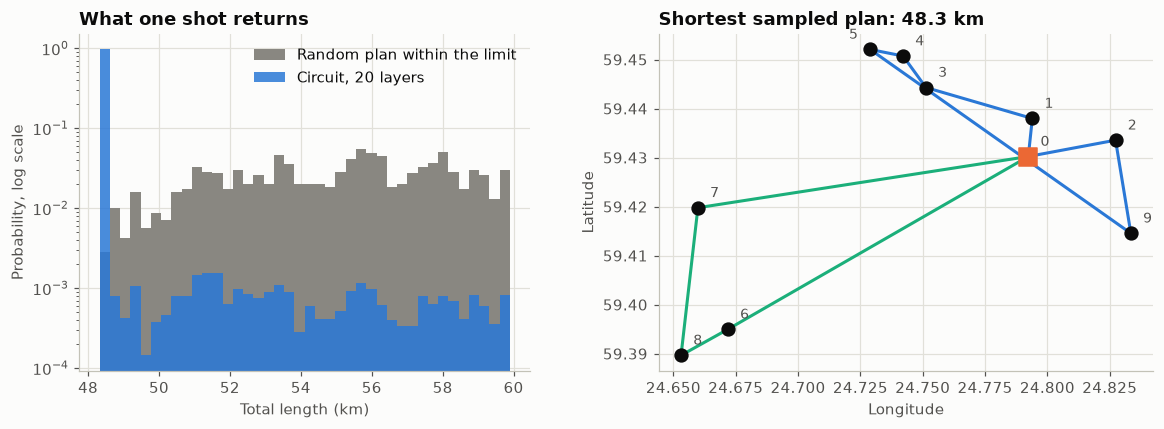

In [22]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.25]})
ok_km = inst.total[hard.rows] / 1000
bins = np.linspace(ok_km.min(), ok_km.max(), 41)
left.hist(ok_km, bins=bins, weights=np.full(len(ok_km), 1 / len(ok_km)), color=MUTED, label="Random plan within the limit")
left.hist(ok_km, bins=bins, weights=showcase_probs, color=BLUE, alpha=0.85, label=f"Circuit, {SHOWCASE[1]} layers")
left.set_yscale("log")
left.set_xlabel("Total length (km)"); left.set_ylabel("Probability, log scale")
left.set_title("What one shot returns"); left.legend(loc="upper right")
sampled_best = min(merged, key=lambda routes: (max(routes_metres(routes, inst.d)) > inst.limit, sum(routes_metres(routes, inst.d))))
draw_map(right, N_LOCATIONS, sampled_best)
right.set_title(f"Shortest sampled plan: {sum(routes_metres(sampled_best, inst.d)) / 1000:.1f} km")
plt.tight_layout(); plt.show()

# 9. Benchmarks

## Does the hard limit matter? The soft-limit circuit

The usual way to handle a rule is a penalty. We build that circuit for comparison. It is the one-van circuit on 11 points:

- **Start state:** all 3,628,800 plans, with no amplitude amplification.
- **Mixer:** plain 2-opt reversals, with no limit check.
- **Cost phase:** the total length, plus a penalty for a plan over the limit: 9 km, plus the distance by which its routes exceed the limit.

The penalty must be larger than the most that breaking the limit can save. Here that is 8.1 km: the shortest plan within the limit minus the one-van tour. We use 9 km. A wrong penalty makes the circuit prefer a plan that breaks the limit.

The cost phase needs the limit check once per layer, so one shot costs layers + 1 cost evaluations. This circuit only gets the linear ramp. Training more angles on 3.6 million plans takes too long in the simulator.

In [23]:
SOFT_SLOPES_BETA = (0.05, 0.1, 0.15, 0.2)
SOFT_SLOPES_GAMMA = (2.0, 3.0, 4.0, 5.0)

over_by = np.maximum(inst.first - inst.limit, 0) + np.maximum(inst.second - inst.limit, 0)
soft_cost = inst.total + np.where(inst.ok, 0, int(SOFT_STEP_KM * 1000)) + over_by
assert ((soft_cost == soft_cost.min()) == inst.best).all(), "The penalty is too small: a plan over the limit has the lowest cost"
print(f"Smallest penalty that works without the extra-distance term: {km((inst.shortest - inst.total[~inst.ok]).max())} km")

start_time = time.perf_counter()
soft = PlanQAOA(inst, np.ones(len(inst.plans), dtype=bool), soft_cost, reversal_moves(M))
print(f"Soft-limit simulator: {len(soft.rows):,} plans, {len(soft.lo):,} pairs, built in {time.perf_counter() - start_time:.0f} s")

soft_results = {}
for layers in DEPTHS_SOFT:
    betas, gammas, evaluations, seconds = cached_angles(f"n{N_LOCATIONS}_soft_ramp_p{layers}",
                                                        lambda: best_ramp(soft, layers, SOFT_SLOPES_BETA, SOFT_SLOPES_GAMMA))
    angles["soft ramp", layers] = (betas, gammas, evaluations, seconds)
    soft_results[layers] = measures(soft, soft.probabilities(betas, gammas), layers + 1)
del soft

show_table(["Circuit", "Layers", "P(opt)", "P(valid)", "Mean gap of valid shots", "Shots to 99 %", "Cost evaluations per shot", "Cost evaluations to 99 %"],
           [[name, layers, pct(r["p_opt"]), pct(r["p_valid"]), pct(r["gap"]), f"{r['shots']:,}", f"{r['per_shot']:,}", f"{r['evaluations']:,}"]
            for name, layers, r in [("Soft limit, linear ramp", layers, soft_results[layers]) for layers in DEPTHS_SOFT]
            + [("Hard limit, linear ramp", layers, results["ramp", layers]) for layers in DEPTHS_SOFT]])

Smallest penalty that works without the extra-distance term: 8.120 km


Soft-limit simulator: 3,628,800 plans, 79,833,600 pairs, built in 15 s


| Circuit | Layers | P(opt) | P(valid) | Mean gap of valid shots | Shots to 99 % | Cost evaluations per shot | Cost evaluations to 99 % |
|---|---|---|---|---|---|---|---|
| Soft limit, linear ramp | 20 | 5.6 % | 78.2 % | 2.9 % | 81 | 21 | 1,701 |
| Soft limit, linear ramp | 40 | 11.5 % | 94.1 % | 1.5 % | 38 | 41 | 1,558 |
| Hard limit, linear ramp | 20 | 24.7 % | 99.9 % | 4.1 % | 17 | 1,801 | 30,617 |
| Hard limit, linear ramp | 40 | 32.3 % | 99.9 % | 2.4 % | 12 | 3,581 | 42,972 |

The two circuits trade in opposite directions:

- **Hard limit:** nearly every shot is a valid plan, and far more shots are a shortest plan at the same depth. Each shot is expensive, because every mixer move checks the limit.
- **Soft limit:** many shots break the limit and few are a shortest plan. Each shot is cheap, because the limit is checked once per layer.

## Cost to find the answer

How many cost evaluations does each method need for a 99 % chance of having seen a shortest plan?

- **Random sampling:** draw plans at random.
- **Grover adaptive search** (reference 11): the textbook quantum method with a proven square-root speed-up. It repeats Grover search for "a plan within the limit that is shorter than the best so far". It is simulated here from the exact Grover success probabilities.
- **QAOA:** shots × cost evaluations per shot, for the best depth at each level of tuning. Training cost is extra and is listed in the next table.

In [24]:
def grover_adaptive_search(valid_costs, plans, rng, growth=1.2):
    """Cost evaluations until Dürr-Høyer minimum finding first measures a shortest valid plan.

    `valid_costs` are the costs of the valid plans, sorted. `plans` is the number of all plans.
    """
    current, evaluations, limit = len(valid_costs), 1, 1.0    # current: how many valid plans are shorter than the best so far
    if rng.random() < len(valid_costs) / plans:
        current = int(np.searchsorted(valid_costs, valid_costs[rng.integers(len(valid_costs))]))
    while current > 0:
        iterations = int(rng.integers(0, math.ceil(limit)))
        evaluations += iterations + 1
        if rng.random() < math.sin((2 * iterations + 1) * math.asin(math.sqrt(current / plans))) ** 2:
            current, limit = int(np.searchsorted(valid_costs, valid_costs[rng.integers(current)])), 1.0
        else:
            limit = min(limit * growth, math.sqrt(plans))
    return evaluations


rng = np.random.default_rng(SEED)
valid_costs = np.sort(inst.total[inst.ok])
gas_runs = np.array([grover_adaptive_search(valid_costs, len(inst.plans), rng) for _ in range(2000)])
GAS_EVALUATIONS = int(np.percentile(gas_runs, 99))

cost_rows = [["Random sampling", f"{shots_for_99(P_RANDOM):,}"],
             ["Listing every plan", f"{len(inst.plans):,}"],
             ["Grover adaptive search", f"{GAS_EVALUATIONS:,}"]]
best_soft = min(soft_results, key=lambda layers: soft_results[layers]["evaluations"])
cost_rows.append([f"Soft limit, ramp, {best_soft} layers", f"{soft_results[best_soft]['evaluations']:,} ({soft_results[best_soft]['shots']} shots)"])
for level in ("ramp", "per layer", "per move"):
    layers, r = min(((layers, r) for (lv, layers), r in results.items() if lv == level), key=lambda item: item[1]["evaluations"])
    cost_rows.append([f"Hard limit, {level}, {layers} layers", f"{r['evaluations']:,} ({r['shots']} shot{'s' if r['shots'] != 1 else ''})"])
show_table(["Method", "Cost evaluations for 99 %"], cost_rows)
print(f"For scale: there are {len(inst.plans) // 8:,} different pairs of routes, and {inst.ok.sum() // 8} of them are within the limit.")

| Method | Cost evaluations for 99 % |
|---|---|
| Random sampling | 2,088,903 |
| Listing every plan | 3,628,800 |
| Grover adaptive search | 4,241 |
| Soft limit, ramp, 40 layers | 1,558 (38 shots) |
| Hard limit, ramp, 20 layers | 30,617 (17 shots) |
| Hard limit, per layer, 20 layers | 12,607 (7 shots) |
| Hard limit, per move, 10 layers | 2,733 (3 shots) |

For scale: there are 453,600 different pairs of routes, and 697 of them are within the limit.


**Reading the table**

- The soft-limit circuit needs the fewest cost evaluations, with only two tuned numbers.
- The hard-limit circuit comes close only with one angle per move. That circuit returns a shortest plan in most shots, but it is far more expensive to train.
- With a ramp or one angle per layer, the hard-limit circuit needs more cost evaluations than Grover adaptive search. Its limit checks cost more than its better shots save.

For this problem the penalty is the better trade. This differs from the one-van problem, where keeping the rule exact cost almost nothing. There the rule was built into the order of the stops. Here the rule needs arithmetic, and the hard limit repeats that arithmetic for every move.

## What training costs

The simulator gets all slopes from one forward and one backward pass. Hardware cannot: every tuned number needs at least two extra circuits per gradient, and every circuit needs many shots. The last column is that hardware estimate. The heavily trained circuits cost far more to train than listing every plan. They show what the circuit can express, not a practical way to find the answer.

In [25]:
training_rows = []
for (level, layers), (betas, gammas, evaluations, seconds) in angles.items():
    numbers = 2 if level in ("ramp", "soft ramp") else tuned_numbers(level, layers)
    hardware = evaluations if numbers == 2 else evaluations * (1 + 2 * numbers)
    training_rows.append([{"soft ramp": "soft limit, ramp"}.get(level, level), layers, numbers, f"{evaluations:,}", f"{seconds:,.0f}", f"{hardware:,}"])
show_table(["Angles", "Layers", "Tuned numbers", "Simulator evaluations", "Seconds on this laptop", "Circuits on hardware"], training_rows)

| Angles | Layers | Tuned numbers | Simulator evaluations | Seconds on this laptop | Circuits on hardware |
|---|---|---|---|---|---|
| ramp | 5 | 2 | 25 | 0 | 25 |
| ramp | 10 | 2 | 25 | 0 | 25 |
| ramp | 20 | 2 | 25 | 0 | 25 |
| ramp | 40 | 2 | 25 | 0 | 25 |
| ramp | 80 | 2 | 25 | 0 | 25 |
| per layer | 5 | 10 | 45 | 0 | 945 |
| per layer | 10 | 20 | 122 | 1 | 5,002 |
| per layer | 20 | 40 | 628 | 16 | 50,868 |
| per layer | 40 | 80 | 622 | 46 | 100,142 |
| per move | 5 | 225 | 703 | 9 | 317,053 |
| per move | 10 | 450 | 2,583 | 47 | 2,327,283 |
| per move | 20 | 900 | 2,565 | 66 | 4,619,565 |
| soft limit, ramp | 20 | 2 | 16 | 90 | 16 |
| soft limit, ramp | 40 | 2 | 16 | 180 | 16 |

# 10. Scaling from 5 to 10 locations

Here nothing is tuned per instance. We take the 20-layer ramp found for 10 locations and reuse it unchanged on the smaller instances. Each instance gets its own limit: 75 % of its own shortest one-van tour.

The table is also the reference for other solutions: it lists the exact answer for every size.

| Locations | Limit (km) | Shortest plan (km) | Routes | Plans | Within the limit | Shortest plans |
|---|---|---|---|---|---|---|
| 5 | 12.737 | 17.956 | 0 → 1 → 3 → 4 → 0 and 0 → 2 → 0 | 120 | 16 | 8 |
| 6 | 13.733 | 21.703 | 0 → 1 → 2 → 0 and 0 → 3 → 4 → 5 → 0 | 720 | 32 | 16 |
| 7 | 22.593 | 36.961 | 0 → 2 → 1 → 3 → 4 → 5 → 0 and 0 → 6 → 0 | 5,040 | 160 | 16 |
| 8 | 25.080 | 41.065 | 0 → 2 → 1 → 3 → 4 → 5 → 0 and 0 → 6 → 7 → 0 | 40,320 | 224 | 32 |
| 9 | 27.451 | 44.226 | 0 → 2 → 1 → 3 → 4 → 5 → 0 and 0 → 6 → 8 → 7 → 0 | 362,880 | 640 | 32 |
| 10 | 30.153 | 48.325 | 0 → 1 → 3 → 4 → 5 → 9 → 2 → 0 and 0 → 6 → 8 → 7 → 0 | 3,628,800 | 5,576 | 8 |

| Locations | Qubits | Amplification rounds | P(opt), QAOA ramp | P(valid) | P(opt), random plan within the limit | P(opt), random plan | Mean gap |
|---|---|---|---|---|---|---|---|
| 5 | 100 | 2 | 68.0 % | 91.4 % | 50.0 % | 6.7 % | 3.5 % |
| 6 | 111 | 3 | 66.5 % | 99.3 % | 50.0 % | 2.2 % | 7.1 % |
| 7 | 124 | 4 | 52.4 % | 99.8 % | 10.0 % | 0.32 % | 3.1 % |
| 8 | 139 | 10 | 66.8 % | 100.0 % | 14.3 % | 0.079 % | 2.3 % |
| 9 | 156 | 18 | 86.1 % | 100.0 % | 5.0 % | 0.0088 % | 1.7 % |
| 10 | 175 | 20 | 24.7 % | 99.9 % | 0.14 % | 0.00022 % | 4.1 % |

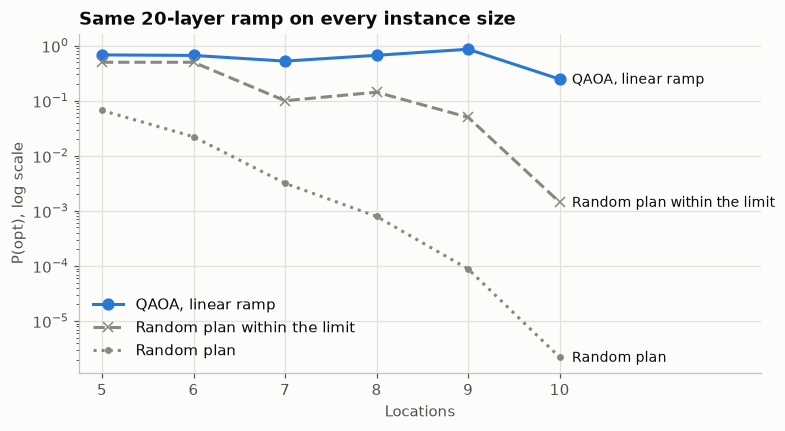

In [26]:
SCALING_LAYERS = 20
ramp_betas, ramp_gammas = angles["ramp", SCALING_LAYERS][:2]
scaling = []
for n in range(5, N_LOCATIONS + 1):
    smaller = inst if n == N_LOCATIONS else make_instance(n)
    circuit, rounds = (hard, PREP_ROUNDS) if n == N_LOCATIONS else hard_limit_circuit(smaller)
    r = measures(circuit, circuit.probabilities(ramp_betas, ramp_gammas), hard_evaluations_per_shot(SCALING_LAYERS, rounds, circuit.num_moves))
    one_best = smaller.plans[smaller.best][0]
    scaling.append((n, smaller, rounds, r, same_routes(routes_of(one_best))))

show_table(["Locations", "Limit (km)", "Shortest plan (km)", "Routes", "Plans", "Within the limit", "Shortest plans"],
           [[n, km(s.limit), km(s.shortest), routes_text(routes), f"{len(s.plans):,}", f"{s.ok.sum():,}", s.best.sum()] for n, s, _, _, routes in scaling])
show_table(["Locations", "Qubits", "Amplification rounds", "P(opt), QAOA ramp", "P(valid)", "P(opt), random plan within the limit", "P(opt), random plan", "Mean gap"],
           [[n, Layout(n).qubits, rounds, pct(r["p_opt"]), pct(r["p_valid"]), pct(s.best.sum() / s.ok.sum()), pct(s.best.mean()), pct(r["gap"])]
            for n, s, rounds, r, _ in scaling])

fig, ax = plt.subplots(figsize=(8, 4))
sizes = [row[0] for row in scaling]
for label, values, color, marker, style in (
        ("QAOA, linear ramp", [row[3]["p_opt"] for row in scaling], BLUE, "o", "-"),
        ("Random plan within the limit", [row[1].best.sum() / row[1].ok.sum() for row in scaling], MUTED, "x", "--"),
        ("Random plan", [row[1].best.mean() for row in scaling], MUTED, ".", ":")):
    ax.plot(sizes, values, color=color, marker=marker, linestyle=style, label=label)
    ax.annotate(label, (sizes[-1], values[-1]), xytext=(8, -3), textcoords="offset points", fontsize=9)
ax.set_yscale("log"); ax.set_xlim(right=sizes[-1] + 2.2); ax.set_xticks(sizes)
ax.set_xlabel("Locations"); ax.set_ylabel("P(opt), log scale")
ax.set_title(f"Same {SCALING_LAYERS}-layer ramp on every instance size"); ax.legend(loc="lower left")
plt.show()

# 11. What the circuit would cost on hardware

We build the parts of the real 175-qubit circuit and translate them to the gates IBM devices use: CX plus one-qubit gates. No qubit layout is applied, so real devices would need more gates for routing.

The soft-limit column is put together from the same parts: one limit check per layer, computed and undone, and plain mixer moves. The few phase gates of its penalty are left out.

In [27]:
def gate_cost(qc):
    return transpile(qc, basis_gates=["cx", "rz", "sx", "x"], optimization_level=1, seed_transpiler=SEED).count_ops().get("cx", 0)


start_time = time.perf_counter()
grid = list(range(M * M))
prepare = QuantumCircuit(lay.qubits)
all_plans_state(prepare, M)
phase_circuit = QuantumCircuit(lay.qubits)
cost_phase(phase_circuit, 1e-4, inst.d, M)
check = QuantumCircuit(lay.qubits)
route_lengths(check, M, inst.d, inst.limit, done, running, lay.scratch)

# One round of amplitude amplification: mark the plans within the limit, then reflect about the all-plans state.
amplify = QuantumCircuit(lay.qubits)
amplify.compose(check, inplace=True)
amplify.x([done[-1], running[-1]]); amplify.cz(done[-1], running[-1]); amplify.x([done[-1], running[-1]])
amplify.compose(check.inverse(), inplace=True)
amplify.compose(prepare.inverse(), inplace=True)
amplify.x(grid); amplify.h(grid[-1]); amplify.mcx(grid[:-1], grid[-1]); amplify.h(grid[-1]); amplify.x(grid)
amplify.compose(prepare, inplace=True)

checked_cx, plain_cx = {}, {}   # CX gates of one mixer move, by the number of steps it reverses
for length in range(2, M):
    checked = QuantumCircuit(lay.qubits)
    limit_checked_move(checked, 0.1, 0, length - 1, M, inst.d, inst.limit)
    plain = QuantumCircuit(lay.qubits)
    reversal_mixer(plain, 0.1, 0, length - 1, M, lay.helper)
    checked_cx[length], plain_cx[length] = gate_cost(checked), gate_cost(plain)

cx = {"all plans": gate_cost(prepare), "cost phase": gate_cost(phase_circuit), "limit check": gate_cost(check), "amplify": gate_cost(amplify)}
hard_mixer = sum(checked_cx[b - a + 1] for a, b in segments(M))
plain_mixer = sum(plain_cx[b - a + 1] for a, b in segments(M))
hard_start = cx["all plans"] + PREP_ROUNDS * cx["amplify"]
hard_layer = cx["cost phase"] + hard_mixer
soft_layer = cx["cost phase"] + 2 * cx["limit check"] + plain_mixer

show_table(["Part", "CX gates"],
           [["All-plans state", f"{cx['all plans']:,}"],
            ["Limit check, computed once", f"{cx['limit check']:,}"],
            ["One round of amplitude amplification", f"{cx['amplify']:,}"],
            [f"Hard limit: start state ({PREP_ROUNDS} rounds)", f"{hard_start:,}"],
            ["Cost phase (per layer)", f"{cx['cost phase']:,}"],
            [f"One limit-checked mixer move", f"{min(checked_cx.values()):,} to {max(checked_cx.values()):,}"],
            [f"Hard limit: mixer, {len(segments(M))} moves (per layer)", f"{hard_mixer:,}"],
            [f"Plain 2-opt mixer, {len(segments(M))} moves (per layer)", f"{plain_mixer:,}"]])
show_table(["Layers", "Hard limit: qubits", "Hard limit: CX gates", "CX error rate for a 50 % chance of a clean run", "Soft limit: qubits", "Soft limit: CX gates"],
           [[layers, lay.qubits, f"{hard_start + layers * hard_layer:,}", f"{math.log(2) / (hard_start + layers * hard_layer):.1e}",
             M * M + 2 + 2 * REGISTER_BITS, f"{cx['all plans'] + layers * soft_layer:,}"] for layers in (5, 10, 20, 40)])
print(f"Counted in {time.perf_counter() - start_time:.0f} s")

| Part | CX gates |
|---|---|
| All-plans state | 2,415 |
| Limit check, computed once | 39,988 |
| One round of amplitude amplification | 85,395 |
| Hard limit: start state (20 rounds) | 1,710,315 |
| Cost phase (per layer) | 1,620 |
| One limit-checked mixer move | 160,760 to 161,540 |
| Hard limit: mixer, 44 moves (per layer) | 7,085,400 |
| Plain 2-opt mixer, 44 moves (per layer) | 12,600 |

| Layers | Hard limit: qubits | Hard limit: CX gates | CX error rate for a 50 % chance of a clean run | Soft limit: qubits | Soft limit: CX gates |
|---|---|---|---|---|---|
| 5 | 175 | 37,145,415 | 1.9e-08 | 138 | 473,395 |
| 10 | 175 | 72,580,515 | 9.6e-09 | 138 | 944,375 |
| 20 | 175 | 143,450,715 | 4.8e-09 | 138 | 1,886,335 |
| 40 | 175 | 285,191,115 | 2.4e-09 | 138 | 3,770,255 |

Counted in 15 s


Today's best devices have a CX error rate near 10⁻³. The hard-limit circuit needs an error rate about 200,000 times lower, which means error-corrected hardware. Almost all of the gates are in the limit checks: one limit-checked move costs about as much as 100 cost phases.

The one-van circuit for the same 10 locations needs 82 qubits and 191,000 CX gates at 20 layers. The second van alone adds little: 19 position qubits and one more item to order. The distance limit is what multiplies the cost, because it has to be worked out with arithmetic inside the circuit. The soft limit pays for that once per layer and needs about 10 times the gates of the one-van circuit. The hard limit pays for it at every mixer move and needs about 750 times the gates.

# 12. Score your own solution

`score_plans` computes the measures from section 8 for any sampler. Decode each shot to a pair of routes first: two tuples of stops, one per van, in driving order. An empty tuple is a van that stays at the depot. Count shots that cannot be decoded under the key `None`.

A shot is valid when every stop appears exactly once and both routes are within the limit.

In [28]:
def score_plans(counts, n=N_LOCATIONS, limit_share=LIMIT_SHARE):
    """Measures for a dictionary {(first route, second route): shots}. Shots that are not two routes go under the key None."""
    instance = inst if (n, limit_share) == (N_LOCATIONS, LIMIT_SHARE) else make_instance(n, limit_share)
    shots = sum(counts.values())
    metres = {routes: routes_metres(routes, instance.d) for routes in counts
              if routes is not None and sorted(routes[0] + routes[1]) == list(range(1, n))}
    valid = {routes: count for routes, count in counts.items() if routes in metres and max(metres[routes]) <= instance.limit}
    valid_shots = sum(valid.values())
    p_opt = sum(count for routes, count in valid.items() if sum(metres[routes]) == instance.shortest) / shots
    mean_metres = sum(sum(metres[routes]) * count for routes, count in valid.items()) / valid_shots if valid else math.nan
    return {"P(valid)": valid_shots / shots, "P(opt)": p_opt, "mean gap": mean_metres / instance.shortest - 1,
            "shots to 99 %": shots_for_99(p_opt), "best km": min((sum(metres[routes]) for routes in valid), default=math.nan) / 1000,
            "shortest km": instance.shortest / 1000, "limit km": instance.limit / 1000}


print("This notebook's shots from section 8:")
for name, value in score_plans(counts).items():
    print(f"  {name}: {value:.4g}")

This notebook's shots from section 8:
  P(valid): 0.999
  P(opt): 0.974
  mean gap: 0.003623
  shots to 99 %: 2
  best km: 48.33
  shortest km: 48.33
  limit km: 30.15


# 13. References

1. M. Bellmore and S. Hong, "Transformation of multisalesman problem to the standard traveling salesman problem", Journal of the ACM 21, 500 (1974). Several vans as one tour through copies of the depot.
2. S. Hadfield and others, "From the Quantum Approximate Optimization Algorithm to a Quantum Alternating Operator Ansatz", Algorithms 12, 34 (2019). Constraint-preserving mixers, and mixers controlled by a feasibility check.
3. A. Bärtschi and S. Eidenbenz, "Grover Mixers for QAOA: Shifting Complexity from Mixer Design to State Preparation", IEEE QCE (2020). Starting from a superposition of all valid answers.
4. G. Brassard, P. Høyer, M. Mosca and A. Tapp, "Quantum amplitude amplification and estimation", Contemporary Mathematics 305, 53 (2002). The start state.
5. T. G. Draper, "Addition on a quantum computer", arXiv:quant-ph/0008033 (2000). Adding in the Fourier basis.
6. R. Herrman and others, "Multi-angle quantum approximate optimization algorithm", Scientific Reports 12, 6781 (2022). One angle per gate.
7. L. Li and others, "Quantum optimization with a novel Gibbs objective function and ansatz architecture search", Physical Review Research 2, 023074 (2020). The training objective.
8. T. Jones and J. Gacon, "Efficient calculation of gradients in classical simulations of variational quantum algorithms", arXiv:2009.02823 (2020). Adjoint differentiation.
9. J. A. Montañez-Barrera and K. Michielsen, "Towards a universal QAOA protocol: Evidence of a scaling advantage in solving some combinatorial optimization problems", arXiv:2405.09169 (2024). Linear-ramp angles.
10. J.-Y. Potvin and J.-M. Rousseau, "An exchange heuristic for routeing problems with time windows", Journal of the Operational Research Society 46, 1433 (1995). The 2-opt* move between two routes.
11. C. Dürr and P. Høyer, "A quantum algorithm for finding the minimum", arXiv:quant-ph/9607014 (1996). Grover adaptive search.